## Step 1 — Import libraries


In [ ]:
import os, glob, time, warnings, joblib
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

print('Libraries imported successfully!')

Libraries imported successfully!


## Step 2 — Load the dataset
The Kaggle *Credit Card Fraud* dataset: 284,807 transactions. `Class` = 0 means genuine, `Class` = 1 means fraud.

This cell finds the data automatically in 3 ways: (1) a `creditcard.csv` already in Colab, (2) a free download from OpenML, (3) asks you to upload the file.

In [ ]:
csv_files = glob.glob('creditcard*.csv')

if csv_files:
    df = pd.read_csv(csv_files[0])
    print('Loaded from file:', csv_files[0])
else:
    try:
        from sklearn.datasets import fetch_openml
        raw = fetch_openml(data_id=1597, as_frame=True).frame
        df = raw.copy()
        df['Class'] = df['Class'].astype(str).astype(int)
        for col in df.columns.drop('Class'):
            df[col] = df[col].astype(float)
        if df['Class'].min() == 1:          # some copies label classes 1/2
            df['Class'] = df['Class'] - 1
        print('Downloaded from OpenML')
    except Exception as e:
        print('Download failed. Please upload creditcard.csv (from Kaggle):')
        from google.colab import files
        uploaded = files.upload()
        df = pd.read_csv(next(iter(uploaded)))

print('Dataset shape:', df.shape)
df.head()

Downloaded from OpenML
Dataset shape: (284807, 30)


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## Step 3 — Understand the data

In [ ]:
print('Rows, columns :', df.shape)
print('Missing values :', df.isnull().sum().sum())
print('Duplicate rows :', df.duplicated().sum())

print('\nTransaction count:')
print(df['Class'].value_counts())
print('\nFraud percentage: %.3f %%' % (df['Class'].mean() * 100))

Rows, columns : (284807, 30)
Missing values : 0
Duplicate rows : 9144

Transaction count:
Class
0    284315
1       492
Name: count, dtype: int64

Fraud percentage: 0.173 %


> **Key point:** fraud is only ~0.17 % of the data. This is **class imbalance** — the main challenge of this project. A lazy model that always says "genuine" would be 99.8 % accurate but catch zero fraud, so we will **not** judge models by accuracy alone.

## Step 4 — Visualise the data

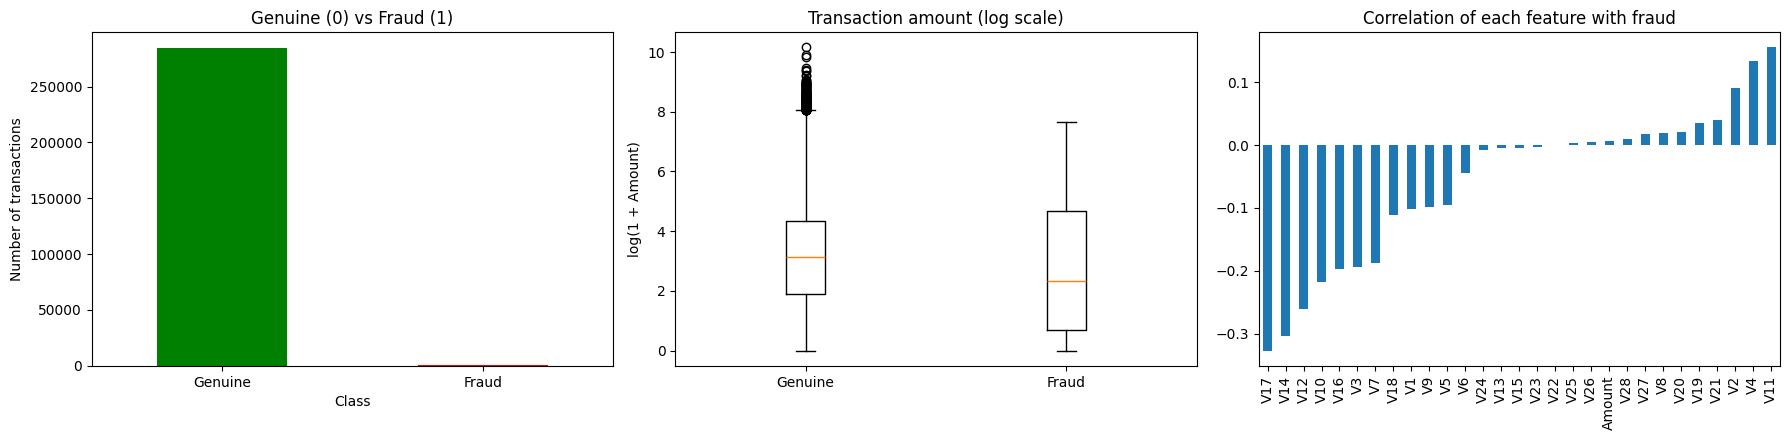

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))

# 1) class balance
df['Class'].value_counts().plot(kind='bar', ax=ax[0], color=['green', 'red'])
ax[0].set_title('Genuine (0) vs Fraud (1)'); ax[0].set_ylabel('Number of transactions')
ax[0].set_xticklabels(['Genuine', 'Fraud'], rotation=0)

# 2) amount by class
ax[1].boxplot([np.log1p(df[df.Class == 0]['Amount']), np.log1p(df[df.Class == 1]['Amount'])])
ax[1].set_xticklabels(['Genuine', 'Fraud'])
ax[1].set_title('Transaction amount (log scale)'); ax[1].set_ylabel('log(1 + Amount)')

# 3) features most correlated with fraud
df.corr()['Class'].drop('Class').sort_values().plot(kind='bar', ax=ax[2])
ax[2].set_title('Correlation of each feature with fraud')

plt.tight_layout(); plt.show()

## Step 5 — Split into training data and testing data
80 % is used to teach the models, 20 % is kept hidden to test them fairly. `stratify=y` keeps the same fraud percentage in both parts.

In [ ]:
X = df.drop(columns='Class')    # inputs (Time, V1..V28, Amount)
y = df['Class']                 # answer we want to predict

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print('Training rows:', len(X_train), '| frauds:', y_train.sum())
print('Testing rows :', len(X_test),  '| frauds:', y_test.sum())

# how many times rarer fraud is (used by XGBoost)
weight = (y_train == 0).sum() / (y_train == 1).sum()
print('Genuine : Fraud ratio = %.0f : 1' % weight)

Training rows: 227845 | frauds: 394
Testing rows : 56962 | frauds: 98
Genuine : Fraud ratio = 577 : 1


## Step 6 — Create the 5 models
To handle imbalance we use **class weighting**: we tell each model *"a mistake on a fraud counts much more than a mistake on a genuine transaction"*.

| Model | Idea |
|---|---|
| Logistic Regression | simple formula, needs scaled data (we scale inside) |
| Decision Tree | a flow-chart of yes/no questions |
| Random Forest | many trees voting together |
| XGBoost | trees built one after another, each fixing earlier mistakes |
| LightGBM | a faster version of boosting |

In [ ]:
models = {
    'Logistic Regression': make_pipeline(StandardScaler(),
                               LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)),
    'Decision Tree': DecisionTreeClassifier(max_depth=8, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=50, max_depth=10, class_weight='balanced_subsample',
                               n_jobs=-1, random_state=42),
    'XGBoost': XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.1, scale_pos_weight=weight,
                               tree_method='hist', n_jobs=-1, random_state=42),
    'LightGBM': LGBMClassifier(n_estimators=100, learning_rate=0.1, class_weight='balanced',
                               n_jobs=-1, random_state=42, verbose=-1),
}
print('Models ready:', list(models))

Models ready: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost', 'LightGBM']


## Step 7 — Train every model and evaluate it
For each model: **fit** (learn from training data) → **predict** (on the hidden test data) → measure scores.

- **Precision** – of the transactions we flagged as fraud, how many really were fraud?
- **Recall** – of all real frauds, how many did we catch?
- **F1** – balance between precision and recall.
- **PR-AUC** – overall quality on imbalanced data (our main score).
- **ROC-AUC** – overall ranking quality.

In [ ]:
rows, probs, preds = [], {}, {}

for name, model in models.items():
    start = time.time()
    model.fit(X_train, y_train)                       # learn
    prob = model.predict_proba(X_test)[:, 1]          # fraud probability (0 to 1)
    pred = (prob >= 0.5).astype(int)                  # 1 = fraud if probability >= 50 %
    probs[name], preds[name] = prob, pred
    rows.append({
        'Model': name,
        'Accuracy':  accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall':    recall_score(y_test, pred),
        'F1 Score':  f1_score(y_test, pred),
        'ROC-AUC':   roc_auc_score(y_test, prob),
        'PR-AUC':    average_precision_score(y_test, prob),
        'Train time (s)': time.time() - start,
    })
    print(f'{name:20s} trained in {time.time() - start:5.1f} s')

results_df = pd.DataFrame(rows).sort_values('PR-AUC', ascending=False).round(4).reset_index(drop=True)
results_df

Logistic Regression  trained in   2.3 s
Decision Tree        trained in  25.7 s
Random Forest        trained in  84.0 s
XGBoost              trained in   3.3 s
LightGBM             trained in   6.1 s


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC,Train time (s)
0,LightGBM,0.9993,0.7830,0.8469,0.8137,0.9653,0.8635,6.0907
1,Random Forest,0.9993,0.7664,0.8367,0.8000,0.9814,0.8010,83.9525
2,XGBoost,0.9968,0.3307,0.8673,0.4789,0.9772,0.7932,3.2845
3,Logistic Regression,0.9745,0.0586,0.9184,0.1101,0.9714,0.7182,2.2883
4,Decision Tree,0.9806,0.0707,0.8469,0.1305,0.9182,0.4709,25.7280


## Step 8 — Compare the models

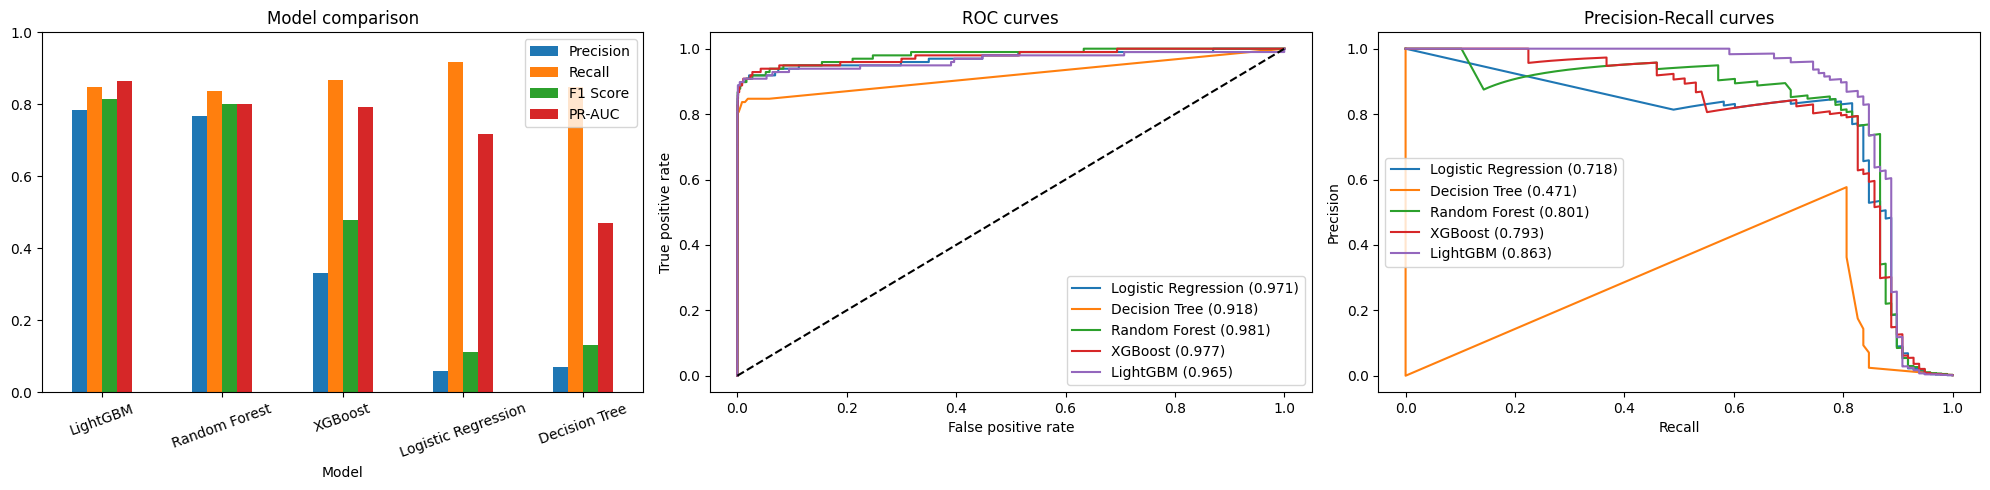

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5))

# bar chart of the main scores
results_df.set_index('Model')[['Precision', 'Recall', 'F1 Score', 'PR-AUC']].plot(kind='bar', ax=ax[0])
ax[0].set_title('Model comparison'); ax[0].set_ylim(0, 1); ax[0].tick_params(axis='x', rotation=20)

# ROC curves
for name in models:
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    ax[1].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, probs[name]):.3f})")
ax[1].plot([0, 1], [0, 1], 'k--'); ax[1].set_title('ROC curves')
ax[1].set_xlabel('False positive rate'); ax[1].set_ylabel('True positive rate'); ax[1].legend()

# Precision-Recall curves
for name in models:
    p, r, _ = precision_recall_curve(y_test, probs[name])
    ax[2].plot(r, p, label=f"{name} ({average_precision_score(y_test, probs[name]):.3f})")
ax[2].set_title('Precision-Recall curves'); ax[2].set_xlabel('Recall'); ax[2].set_ylabel('Precision'); ax[2].legend()

plt.tight_layout(); plt.show()

## Step 9 — Where do the models make mistakes? (Confusion matrices)
Top-left = genuine correctly passed · Bottom-right = fraud caught · Top-right = **false alarms** · Bottom-left = **missed frauds** (most costly).

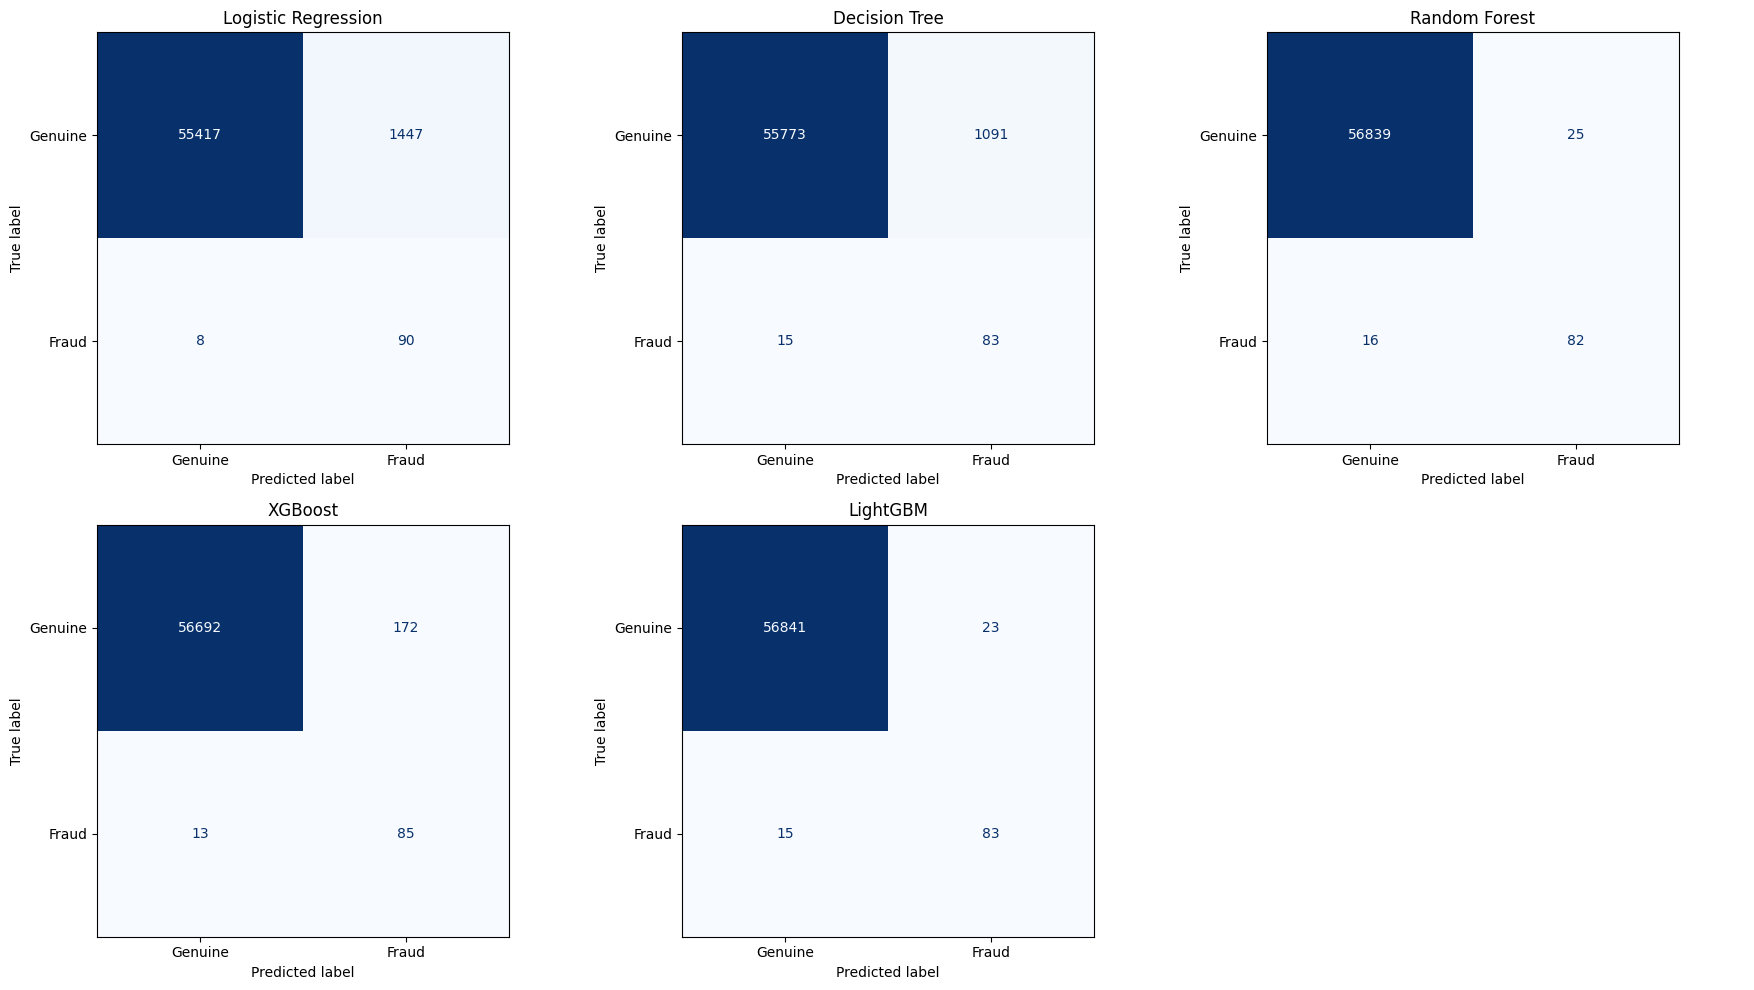

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
for ax, name in zip(axes, models):
    ConfusionMatrixDisplay(confusion_matrix(y_test, preds[name]),
                           display_labels=['Genuine', 'Fraud']).plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(name)
axes[-1].axis('off')
plt.tight_layout(); plt.show()

## Step 10 — Which features matter most? (Interpretation)

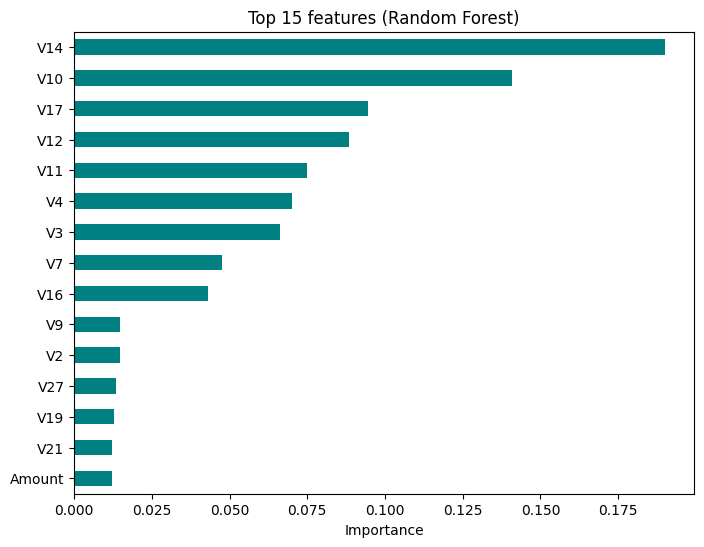

In [ ]:
importance = pd.Series(models['Random Forest'].feature_importances_, index=X.columns).sort_values(ascending=False)

importance.head(15).sort_values().plot(kind='barh', figsize=(8, 6), color='teal')
plt.title('Top 15 features (Random Forest)'); plt.xlabel('Importance'); plt.show()

> V1–V28 are anonymised features (PCA) because real bank data is confidential, so we can say *which* features matter but not their real-world meaning.

## Step 11 — Choose the best model
We pick the model with the highest **PR-AUC**, the most reliable score for imbalanced data.

In [ ]:
best_name = results_df.loc[0, 'Model']          # table is already sorted by PR-AUC
best_model = models[best_name]
print('🏆 Best model:', best_name)
print()
print(results_df.to_string(index=False))
print('\nDetailed report for', best_name)
print(classification_report(y_test, preds[best_name], target_names=['Genuine', 'Fraud'], digits=4))

cm = confusion_matrix(y_test, preds[best_name])
print(f'Frauds caught: {cm[1,1]} of {cm[1].sum()}  |  Frauds missed: {cm[1,0]}  |  False alarms: {cm[0,1]}')

🏆 Best model: LightGBM

              Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC  PR-AUC  Train time (s)
           LightGBM    0.9993     0.7830  0.8469    0.8137   0.9653  0.8635          6.0907
      Random Forest    0.9993     0.7664  0.8367    0.8000   0.9814  0.8010         83.9525
            XGBoost    0.9968     0.3307  0.8673    0.4789   0.9772  0.7932          3.2845
Logistic Regression    0.9745     0.0586  0.9184    0.1101   0.9714  0.7182          2.2883
      Decision Tree    0.9806     0.0707  0.8469    0.1305   0.9182  0.4709         25.7280

Detailed report for LightGBM
              precision    recall  f1-score   support

     Genuine     0.9997    0.9996    0.9997     56864
       Fraud     0.7830    0.8469    0.8137        98

    accuracy                         0.9993     56962
   macro avg     0.8914    0.9233    0.9067     56962
weighted avg     0.9994    0.9993    0.9993     56962

Frauds caught: 83 of 98  |  Frauds missed: 15  |  False alarms: 23


## Step 12 — Save the model and results
These files are used in the next step (dashboard + GitHub). The model is compressed to stay under GitHub's 100 MB limit.

In [ ]:
os.makedirs('models', exist_ok=True)

bundle = {'model': best_model, 'model_name': best_name, 'scaler': None,   # Logistic Regression scales inside its pipeline
          'feature_names': list(X.columns)}
joblib.dump(bundle, 'models/fraud_detection_model.pkl', compress=3)

results_df.to_csv('model_comparison.csv', index=False)
importance.to_csv('feature_importance.csv', header=['importance'])

# a few unseen transactions for the live dashboard demo (all test frauds + 2000 genuine)
demo = pd.concat([X_test[y_test == 1].assign(Class=1),
                  X_test[y_test == 0].sample(2000, random_state=1).assign(Class=0)])
demo.sample(frac=1, random_state=1).to_csv('demo_transactions.csv', index=False)

print('Model size (MB):', round(os.path.getsize('models/fraud_detection_model.pkl') / 1e6, 1), '(must be under 100)')
print('Saved:', ['models/fraud_detection_model.pkl', 'model_comparison.csv', 'feature_importance.csv', 'demo_transactions.csv'])

Model size (MB): 0.2 (must be under 100)
Saved: ['models/fraud_detection_model.pkl', 'model_comparison.csv', 'feature_importance.csv', 'demo_transactions.csv']


In [ ]:
# Download everything as one zip file to your computer
import shutil
shutil.make_archive('fraud_project_files', 'zip', '.', 'models')   # model folder
import zipfile
with zipfile.ZipFile('fraud_project_files.zip', 'a') as z:
    for f in ['model_comparison.csv', 'feature_importance.csv', 'demo_transactions.csv']:
        z.write(f)
try:
    from google.colab import files
    files.download('fraud_project_files.zip')
except Exception:
    print('Download from the Files panel on the left: fraud_project_files.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import sklearn, xgboost, lightgbm
print("scikit-learn==" + sklearn.__version__)
print("xgboost==" + xgboost.__version__)
print("lightgbm==" + lightgbm.__version__)

scikit-learn==1.6.1
xgboost==3.4.1
lightgbm==4.6.0


In [ ]:
!ls -lh models/

total 156K
-rw-r--r-- 1 root root 153K Nov 25 19:27 fraud_detection_model.pkl
